# human_cohort2_60m Cell Graph

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 21.12.2024
- Date of Last Modification: 10.02.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries 

In [18]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [19]:
import sys
sys.path.append("../../utils")

In [20]:
import logging
import os
import pickle
import random
from datetime import datetime

import anndata as ad
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
import seaborn as sns
import squidpy as sq
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from sklearn.model_selection import train_test_split

from nichejepa.datasets import prepare_dataset
from nichejepa.infer import infer
from nichejepa.train import train
from nichejepa.utils.config import create_params_from_YAML_wandb_config
from nichejepa.utils.distributed import init_distributed
from nichejepa.utils.evaluation import clustering_metrics, classification_metrics

from analysis_utils import *

## 1.2 Load Config/Params
All setup will be done in the config file. Please edit that file to continue.

In [34]:
# Set params
dataset = 'human_cohort2_60m' # 64 tokens per cell, 6 neighs
tokenizer = 'cell_graph'
# load_timestamp = '07022025_100659_294' # rank
load_timestamp = '08022025_040131_515' # count
# load_timestamp = '09022025_223810_599' # rank (without centering)
# read_checkpoint = 'nichejepa-ep6.pth.tar' # 0.452, (n)
# read_checkpoint = 'nichejepa-ep5.pth.tar' # 0.343, 0.139
read_checkpoint = 'nichejepa-ep4.pth.tar' # 0.282, 0.575 (y)
# read_checkpoint = 'nichejepa-ep3.pth.tar' # 0.572, 0.565
# read_checkpoint = 'nichejepa-ep2.pth.tar' # 0.597, 0.465, 0.567
# read_checkpoint = 'nichejepa-ep0.pth.tar' # 0.451, 0,498, 0.449
niche_key = 'niche_type'

In [35]:
model_config_folder_path = '../../config/model'
artifacts_folder_path = '../../artifacts'
datasets_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS'

In [36]:
# Set up logger
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

# Load config
if not load_timestamp:
    params = create_params_from_YAML_wandb_config(f'{model_config_folder_path}/{dataset}_{tokenizer}.yaml',logger)
else:
    params = create_params_from_YAML_wandb_config(f'{artifacts_folder_path}/{dataset}/{load_timestamp}/params.yaml',logger)

if read_checkpoint:
    params['state']['read_checkpoint'] = read_checkpoint
if load_timestamp:
    params['state']['load_checkpoint'] = True

params

INFO:root:Loaded parameters from YAML file.


{'data': {'batch_size': 64,
  'dataset_name': 'human_cohort2_60m',
  'n_segments': 7,
  'num_workers': 24,
  'pin_memory': True,
  'precomputed_n_nonzero_tokens': False,
  'precomputed_split': '/lustre/scratch126/cellgen/team361/sb75/nichejepa-reproducibility/analysis/tokenization/precomputed_split',
  'random_state': 0,
  'raw_data_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/silver/xhs1000-39b_1p',
  'sample_subset': False,
  'sampling_strategy': None,
  'seq_len_cell': 64,
  'seq_len_neighborhood': 384,
  'split': 0,
  'stratify': False,
  'token_dict_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/token_dictionary_homo_sapiens_temp.pkl',
  'tokenized_data_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/gold/cell-graph-tokenizer/human_cohort2_60m/human_cohort2_60m_32_None_None_None_None_None_shifted_log_knn_6.dataset',
  'tokenizer_type': 'cell_graph'},
 'mask': {'block_masking': True,
  'context_mask_size': 200,
  'n_contexts': 1,
  'n_

In [37]:
if not load_timestamp:
    current_timestamp = (
        datetime.now().strftime("%d%m%Y_%H%M%S") +
        f"_{datetime.now().microsecond // 1000:03d}")
    folder_path = os.path.join(artifacts_folder_path,
                               params['data']['dataset_name'],
                               current_timestamp)
else:
    folder_path = f'{artifacts_folder_path}/{dataset}/{load_timestamp}'
    
folder_path

'../../artifacts/human_cohort2_60m/08022025_040131_515'

## 1.3 Create Train & Test Dataset

In [38]:
train_dataset, val_dataset, test_dataset = prepare_dataset(params)
train_dataset

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

Dataset({
    features: ['cell_degrees', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value_token', 'gene_panel_value_token', 'assay_value_token', 'species_value_token', 'tissue_value_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens', 'cls_tokens'],
    num_rows: 54070964
})

## 1.4 Run INIT Distributed

In [39]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=random.randint(40000, 50000))
logger.info(f'Running... (rank: {rank}/{world_size})')

INFO:root:Running... (rank: 0/1)


# 2. Model Training

In [ ]:
### Train model
train(params,
      train_dataset,
      test_dataset,
      save_folder_path=folder_path)

# 3. Analysis

## 3.1 Run Model Inference

In [40]:
# Set inference params
layer = params['meta']['enc_depth'] - 1
exclude_unshared_tokens = False # True, False
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'
latent_leiden_resolution = 0.5 # 0.1, 0.5
latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'

In [41]:
# Get gene tokens that do not overlap between gene panels to obtain excluded tokens
if exclude_unshared_tokens:
    with open(gene_panel_gene_mapping_file_path, 'rb') as file:
        gene_panel_gene_mapping = pickle.load(file)
    
    with open(token_dictionary_file_path, 'rb') as file:
        token_dictionary = pickle.load(file)
    
    genes_panel0 = set(gene_panel_gene_mapping['gene_panel0'])
    genes_panel1 = set(gene_panel_gene_mapping['gene_panel1'])
    
    overlapping_genes = list(genes_panel0.intersection(genes_panel1))
    non_overlapping_genes = list(genes_panel0.symmetric_difference(genes_panel1))
    
    overlapping_gene_tokens = [token_dictionary[gene] for gene in overlapping_genes if gene in token_dictionary]
    non_overlapping_gene_tokens = [token_dictionary[gene] for gene in non_overlapping_genes if gene in token_dictionary]
else:
    non_overlapping_gene_tokens = None

In [42]:
# Run model inference
adata = infer(params,
              val_dataset, # train_dataset, val_dataset, test_dataset
              load_folder_path=folder_path,
              agg_type=agg_type,
              masked_tokens=non_overlapping_gene_tokens,
              agg_excluded_tokens=excluded_tokens if exclude_unshared_tokens else None,
              cell_gene_ids=[],
              neighborhood_gene_ids=[]
             )

# Save adata
adata.write(f'{folder_path}/adata_{agg_type}'
            f'{"_shared_genes" if exclude_unshared_tokens and "cls" not in agg_type else ("_all_genes" if "cls" not in agg_type else "")}.h5ad')

None
INFO:root:GeneTransformerCountEncoder(
  (token_embed): Embedding(23407, 1024, padding_idx=0)
  (seg_embed): Embedding(113, 1024, padding_idx=0)
  (blocks): ModuleList(
    (0-5): 6 x Block(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
  (value_embed): Embedding(100,

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/torch/utils/data/dataloader.py:557: UserWarning: This DataLoader will create 24 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(
/lustre/scratch126/cellgen/team361/sb75/nichejepa/src/nichejepa/helper.py:78: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `we

INFO:root:Loaded pretrained encoder from epoch 3 with msg: <All keys matched successfully>.
INFO:root:Loaded pretrained predictor from epoch 3 with msg: <All keys matched successfully>.
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:Loaded pretrained target encoder from epoch 3 with msg: <All keys matched successfully>.
INFO:root:Finished loading checkpoint with read path: ../../artifacts/human_cohort2_60m/08022025_040131_515/nichejepa-ep4.pth.tar.


0it [00:00, ?it/s]/lustre/scratch126/cellgen/team361/sb75/nichejepa/src/nichejepa/infer.py:282: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
875it [01:06, 13.12it/s]
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/ann

                      Class 1                             Class 2  \
0    Perivascular superficial            Perivascular superficial   
1    Perivascular superficial                 Interstitial stroma   
2    Perivascular superficial  Basal epidermis/superficial dermis   
3    Perivascular superficial                 Perivascular depeer   
4    Perivascular superficial                            Sebocyte   
..                        ...                                 ...   
116              Sweat gland2                            KC_T2_LC   
117              Sweat gland2                                  KC   
118              Sweat gland2                       Schwann_KC_HF   
119              Sweat gland2                              Muscle   
120              Sweat gland2                        Sweat gland2   

     Mean Similarity  Variance Similarity  
0           0.912091             0.014691  
1           0.717228             0.037482  
2           0.341307             0.0155

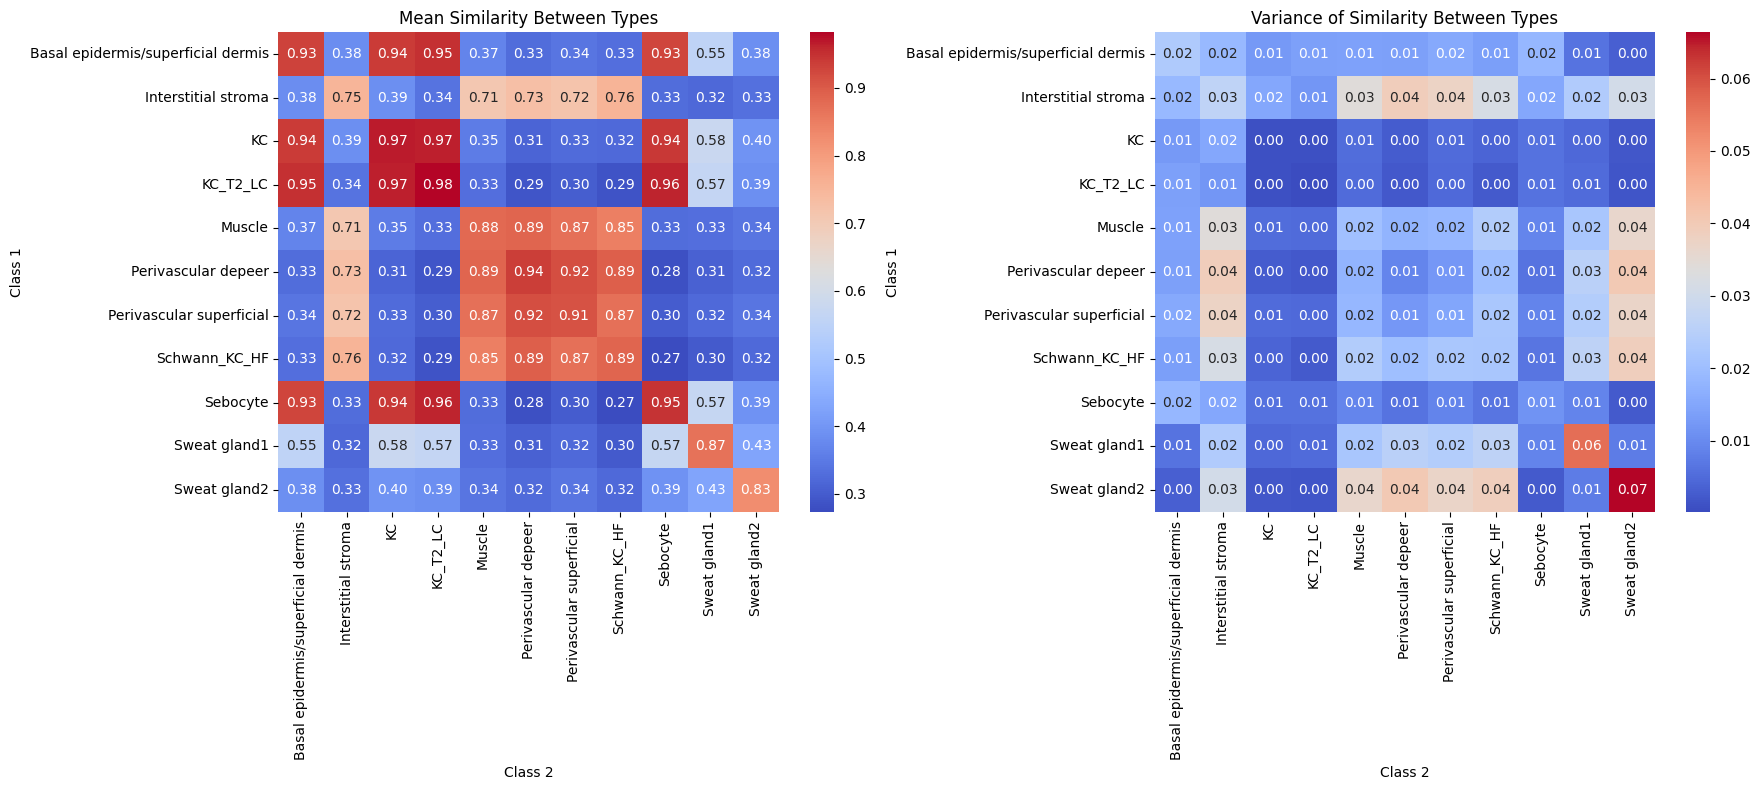

In [43]:
similarity_stats = compute_similarity_stats(
    adata,
    n_samples=None,
    type_key='niche_type',
    embedding_key=f'neighborhood_emb_layer_{layer}')
plot_similarity_heatmaps(similarity_stats)

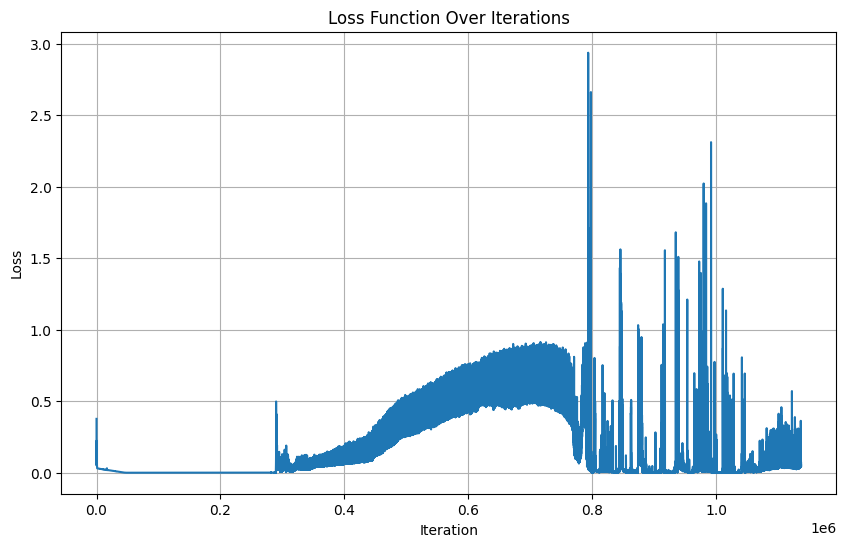

In [44]:
df = pd.read_csv(f'{folder_path}/nichejepa_r0.csv')
df['loss'] = pd.to_numeric(df['loss'], errors='coerce')

plt.figure(figsize=(10, 6))
plt.plot(df.index,df['loss'])
plt.title('Loss Function Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

## 3.2 Plot Embeddings

In [30]:
# Extract batch from cell ID
adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]

In [31]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

In [32]:
# Perform clustering until number of ground truth niches is matched
latent_leiden_resolution = 0.4
i = 0
n_niches = adata.obs[niche_key].nunique()
while (i<25):
    i += 1
    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution)

    n_latent_clusters = adata.obs[latent_cluster_key].nunique()
    print(f"Number of latent clusters {n_latent_clusters}")
    if n_latent_clusters == n_niches:
        break
    elif n_latent_clusters < (n_niches - 5):
        latent_leiden_resolution += 0.02
    elif n_latent_clusters < (n_niches - 3):
        latent_leiden_resolution += 0.01
    elif n_latent_clusters < n_niches:
        latent_leiden_resolution += 0.001
    elif n_latent_clusters > (n_niches + 5):
        latent_leiden_resolution -= 0.02
    elif n_latent_clusters > (n_niches + 3):
        latent_leiden_resolution -= 0.01
    else:
        latent_leiden_resolution -= 0.001

# Compute metrics
adata = adata[~adata.obs[niche_key].isna()] # Remove missing ground truth
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_cluster_key]
nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)
print(f'NMI is {nmi}. ARI is {ari}.')

# Plot UMAPs
os.makedirs(f'{folder_path}/figures', exist_ok=True)
labels = ['batch', niche_key, latent_cluster_key]
# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

# Plot niches in tissue
spot_sizes = [10] * len(adata.obs['batch'].unique().tolist())
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])

Number of latent clusters 20



KeyboardInterrupt



In [226]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')
sc.tl.leiden(adata,
             neighbors_key='neighborhood',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

os.makedirs(f'{folder_path}/figures', exist_ok=True)

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


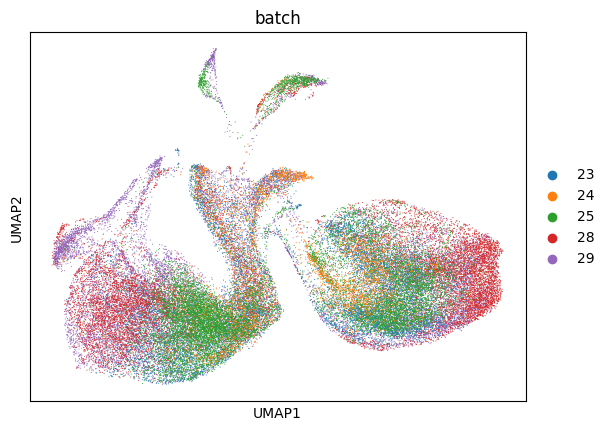

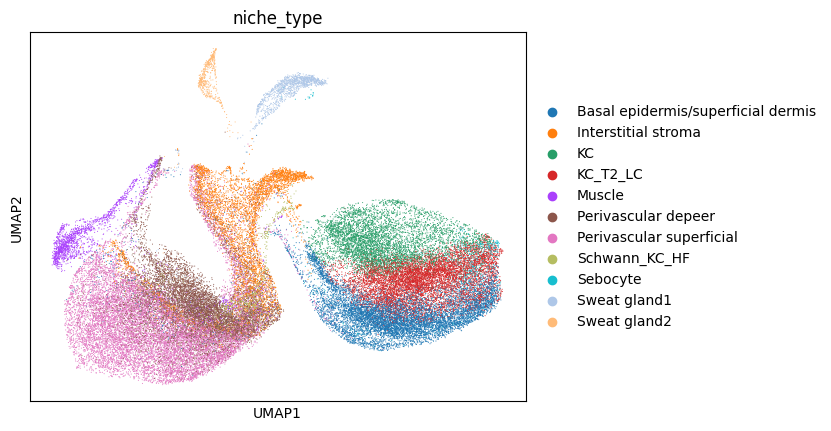

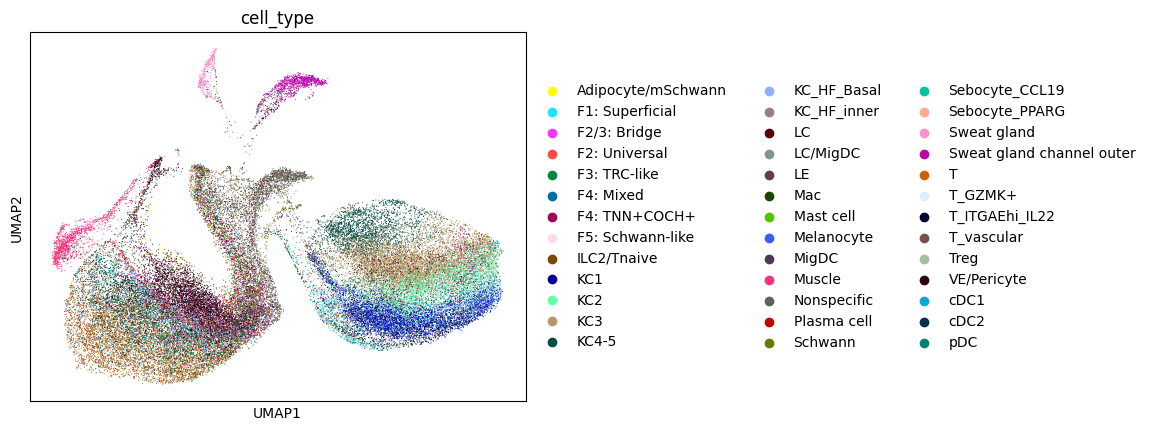

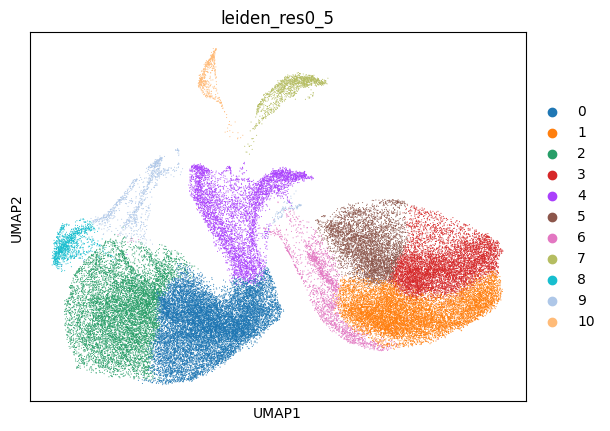

In [227]:
labels = ['batch', 'niche_type', 'cell_type', latent_cluster_key]

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


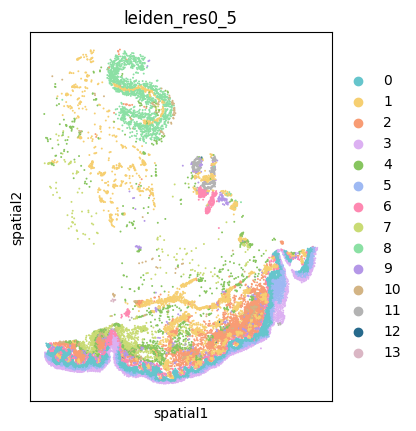

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


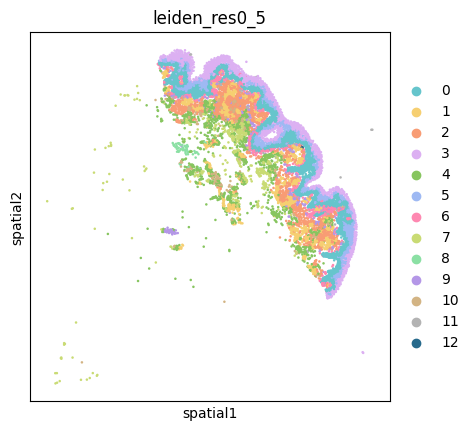

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


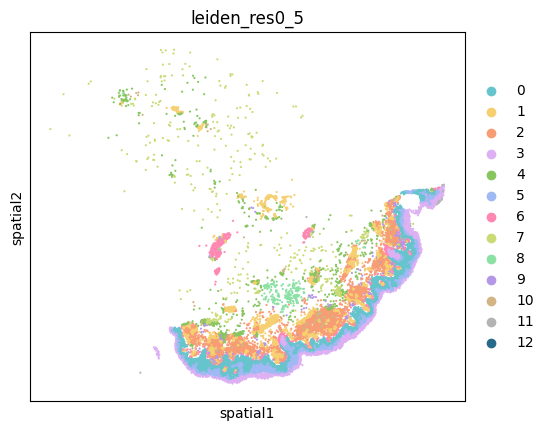

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


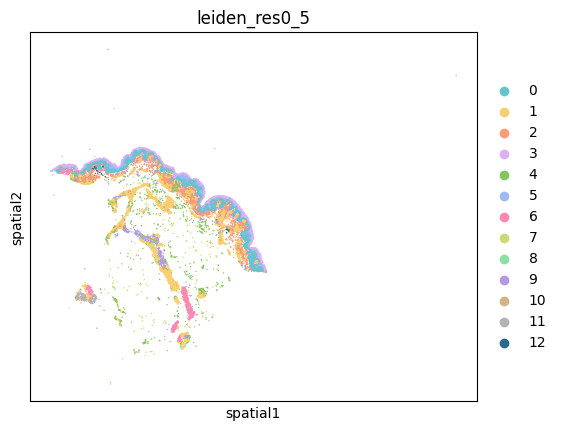

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


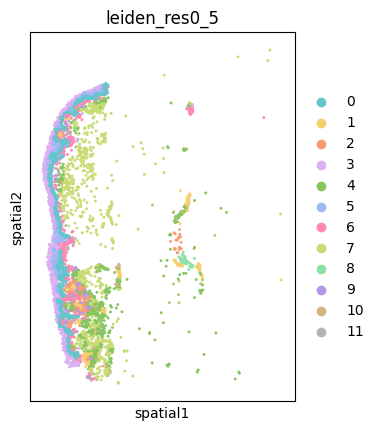

In [16]:
spot_sizes = [20] * len(adata.obs['batch'].unique().tolist())
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])
    #sq.pl.spatial_scatter(adata_batch,
    #                      color=latent_cluster_key,
    #                      shape=None)

In [ ]:
## Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb_layer_{layer}',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')
sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch', 'niche_type', 'cell_type', latent_cluster_key]

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

In [ ]:
spot_sizes = [300, 50]
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])
    #sq.pl.spatial_scatter(adata_batch,
    #                      color=latent_cluster_key,
    #                      shape=None)

In [ ]:
sq.gr.spatial_neighbors(adata,
                        coord_type='generic',
                        spatial_key='spatial',
                        delaunay=True,
                        set_diag=False,
                        )

adata.obs['n_neighbors'] = adata.obsp['spatial_connectivities'].toarray().sum(1)

labels = ['n_neighbors'] # ['major_brain_region', 'Main_molecular_tissue_region']

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

In [ ]:
adata.obs['n_neighbors'].value_counts()

In [ ]:
adata_batch = adata[adata.obs['batch'] == 'batch1']

In [ ]:
sq.pl.spatial_scatter(adata_batch,
                      color=f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}',
                      shape=None)

In [ ]:
adata_test = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/mmb0-1b_smb1-1b_1p_labels/harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad')

In [ ]:
np.min(adata_batch.obsm['spatial'])

In [ ]:
adata_batch.shape

In [ ]:
adata_test.shape

In [ ]:
np.min(adata_test.obsm['spatial'])

In [ ]:
adata_test.obsm['spatial']

In [ ]:
sq.pl.spatial_scatter(adata_test,
                      color='Main_molecular_tissue_region',
                      shape=None)

## 3.3 Plot Embedding Similarity Stats

                      Class 1                             Class 2  \
0    Perivascular superficial            Perivascular superficial   
1    Perivascular superficial                 Interstitial stroma   
2    Perivascular superficial  Basal epidermis/superficial dermis   
3    Perivascular superficial                 Perivascular depeer   
4    Perivascular superficial                            Sebocyte   
..                        ...                                 ...   
116              Sweat gland2                            KC_T2_LC   
117              Sweat gland2                                  KC   
118              Sweat gland2                       Schwann_KC_HF   
119              Sweat gland2                              Muscle   
120              Sweat gland2                        Sweat gland2   

     Mean Similarity  Variance Similarity  
0           0.993322             0.000077  
1           0.992490             0.000097  
2           0.989781             0.0001

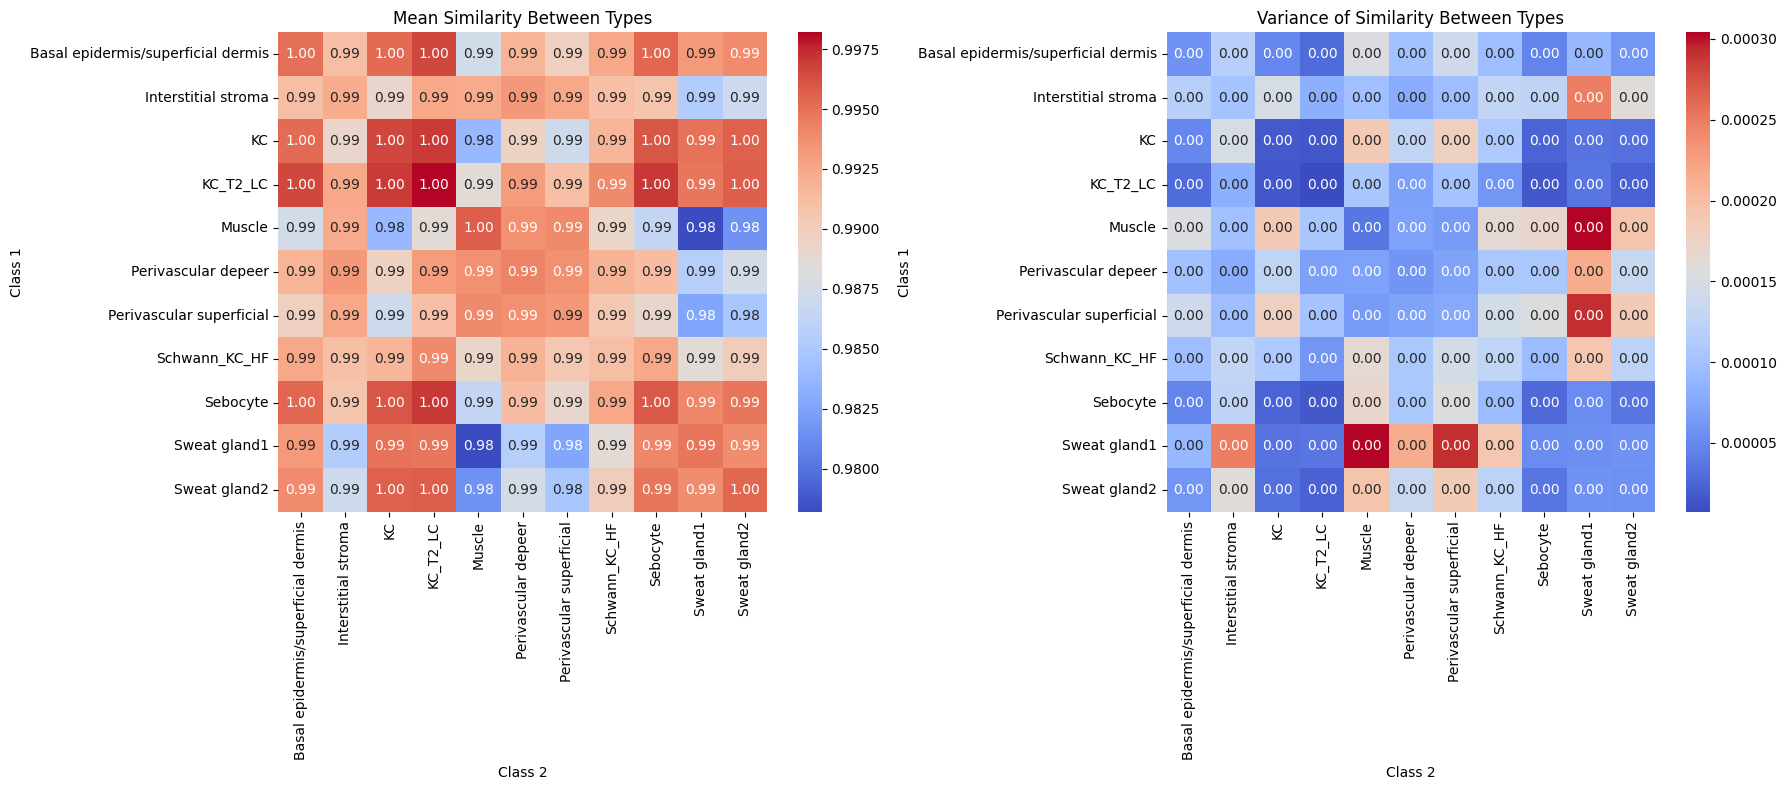

In [33]:
similarity_stats = compute_similarity_stats(
    adata,
    n_samples=None,
    type_key='niche_type',
    embedding_key=f'neighborhood_emb_layer_{layer}')
plot_similarity_heatmaps(similarity_stats)

## 3.4 Compute Metrics

In [ ]:
os.makedirs(f'{folder_path}/metrics', exist_ok=True)

labels = ['cell_types', 'major_brain_region']

# NMI & ARI for label cols (neighborhood embedding)
for label in labels:
    cell_type_metrics = clustering_metrics(
        adata,
        emb_key=f'neighborhood_emb_layer_{layer}',
        label_col=label)
    
    metrics_df = pd.DataFrame([cell_type_metrics])
    metrics_df.to_csv(f'{folder_path}/metrics/{label}_metrics{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.csv', index=False)

## 3.5 Plot Loss Curve

In [ ]:
df = pd.read_csv(f'{folder_path}/nichejepa_r0.csv')
df['loss'] = pd.to_numeric(df['loss'], errors='coerce')

plt.figure(figsize=(10, 6))
plt.plot(df.index,df['loss'])
plt.title('Loss Function Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

In [ ]:
adata_starmap = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/mmb0-1b_smb1-1b_1p_label/starmap_plus_mouse_cns_batch15.h5ad')
adata_merfish = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/mmb0-1b_smb1-1b_1p_label/merfish_mouse_brain_239-batch_batch82.h5ad')

# Check that genes are the same
(adata_starmap.var != adata_merfish.var).any()

# adata_starmap.X.toarray().sum(1)
# adata_merfish.X.toarray().sum(1)

np.mean(adata_merfish.X.sum(1))

np.mean(adata_starmap.X.sum(1))

adata_concat = adata_starmap.concatenate(adata_merfish)

adata_concat.X = adata_concat.X.toarray() / adata_concat.X.toarray().sum(axis=1).reshape(-1, 1) * 10_000
sc.pp.log1p(adata_concat)

adata_concat.X

adata.X.sum(1x).value_counts()

adata_concat.X[0, :].shape

# Get unique values and their counts
unique_values, counts = np.unique(adata_concat.X[1, :], return_counts=True)

# Print the results
for value, count in zip(unique_values, counts):
    print(f"Value {value} occurs {count} times")

plt.hist(adata_concat.X.toarray(), bins=50, edgecolor='black')

sc.pp.neighbors(adata_concat,
                n_neighbors=15,
                use_rep='X')
sc.tl.umap(adata_concat)

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch']

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata_concat,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_pca'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

for i in range(len(test_dataset["gene_tokens"])):
    test_dataset["gene_tokens"][i]

top_k = 10

embedding_dict = {i: np.random.rand(768) for i in range(1672)}
averaged_embeddings = []

for tokens in test_dataset["gene_tokens"]:
    # Filter out the zero tokens
    valid_tokens = [token for token in tokens[:top_k] if token != 0]

    # Retrieve embeddings for the valid tokens
    if valid_tokens:
        embeddings = [embedding_dict[token] for token in valid_tokens]
        
        # Calculate the average embedding across the sequence
        avg_embedding = np.mean(embeddings, axis=0)
    else:
        # If no valid tokens, create a zero vector (or handle as desired)
        avg_embedding = np.zeros(768)
    
    # Append the averaged embedding for this observation
    averaged_embeddings.append(avg_embedding)

# Convert the list of averaged embeddings to a numpy array
averaged_embeddings = np.array(averaged_embeddings)

# Assuming adata is your AnnData object
# Store the averaged embeddings in adata.obsm
adata = ad.AnnData(X=averaged_embeddings)  # Initialize adata or use an existing one

adata.obs['batch'] = [element[0] for element in test_dataset['batch_token']]

sc.pp.neighbors(adata,
                n_neighbors=15)
sc.tl.umap(adata)

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch']

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_random_embed'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

sq.pl.spatial_scatter(adata_starmap,
                      color="major_brain_region",
                      shape=None)

sq.pl.spatial_scatter(adata_merfish,
                      color="major_brain_region",
                      shape=None) 

In [ ]:
import pickle

with open('/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/cell-graph-tokenizer/human_cohort1_50m/token_dictionary.pkl', 'rb') as file:
    token_dict = pickle.load(file)

n_special_values = 0
for key, val in token_dict.items():
    if "spv" in key:
        n_special_values += 1

vocab_size = len(token_dict)

print(f"Number of tokens {vocab_size}.")
print(f"Number of special value tokens {n_special_values}.")

In [ ]:
    max_special_tokens = sum(1 for key in token_dict if "cls" in key) + sum(
        1 for key in token_dict if "spt" in key)

In [ ]:
max_special_tokens

In [ ]:
for key, val in token_dict.items():
    if "spv" in key:
        n_special_values += 1

In [ ]:
item = train_dataset[0]
item2 = train_dataset[1]

In [ ]:
len(train_dataset) # 53M human cells

In [ ]:
cell_ids = train_dataset['cell_id']

In [ ]:
len(cell_ids)

In [ ]:
len(set(cell_ids))

In [ ]:
adata_raw = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/bronze/xhs1000-39b_1p/adata_5k_xenium_skin.h5ad')

batch_mapping_dict = {value: idx for idx, value in enumerate(adata_raw.obs['info_id'].unique().tolist())}

batch_mapping_dict

In [ ]:
adata_annotated_batch = adata[adata.obs['batch'] == 'lung9_rep1']

In [ ]:
adata_annotated_batch.obs.columns

In [ ]:
adata_annotated_batch.obs

In [ ]:
adata_temp =  sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/chl59-8b_1p/Lung9_Rep2+SMI+Flat+data.tar.h5ad')

In [ ]:
adata_temp.obs.columns

In [ ]:
adata_temp.obs

In [ ]:
adata_temp.obs[['cell_id', 'Sanger patient ID', 'Timepoint']]

In [ ]:
cluster_key = 'NICHE_NAMES'
spot_size = 30

In [ ]:
sc.pl.spatial(adata_temp,
              color=cluster_key,
              spot_size=spot_size)

In [ ]:
adata = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/chr78-11b_1p/CM019_annotated.h5ad')

In [ ]:
adata.obs.columns

In [ ]:
adata.obs

In [ ]:
cluster_key = 'broad_anatomy'
spot_size = 100

In [ ]:
sc.pl.spatial(adata,
              color=cluster_key,
              spot_size=spot_size)

In [ ]:
adata_raw.obs['broad_anatomy']

In [ ]:
adata_raw.obs['leiden_log1pnorm_res']

In [ ]:
adata_raw.obs['Sanger patient ID'].unique()

In [ ]:
adata_raw.obs

In [ ]:
{value: idx for idx, value in enumerate(adata_raw.obs['info_id'].unique().tolist())}